In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("Food_Delivery .csv")   # or your full Downloads path
df["order_date"] = pd.to_datetime(df["order_date"])
df["city"] = df["city"].str.strip().str.title().fillna("Unknown")
df.loc[(df.delivery_time_minutes <= 0) | (df.delivery_time_minutes > 120), "delivery_time_minutes"] = np.nan
df["delivery_time_minutes"] = df.groupby("restaurant")["delivery_time_minutes"].transform(lambda s: s.fillna(s.median()))
df.loc[df.quantity > 4, "quantity"] = 4
df = df.drop_duplicates().drop_duplicates(subset="order_id").reset_index(drop=True)
df["order_value"] = df.quantity * df.price * (1 - df.discount / 100)
order = df.restaurant.value_counts().index

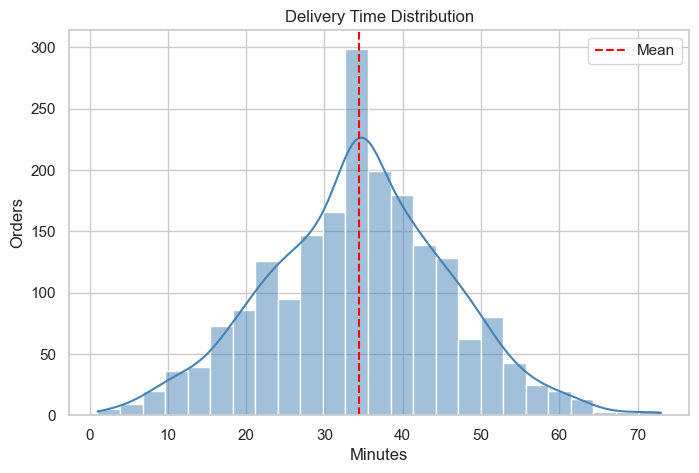

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(df.delivery_time_minutes, bins=25, kde=True, color="steelblue")
plt.axvline(df.delivery_time_minutes.mean(), color="red", linestyle="--", label="Mean")
plt.title("Delivery Time Distribution"); plt.xlabel("Minutes"); plt.ylabel("Orders")
plt.legend(); plt.show()

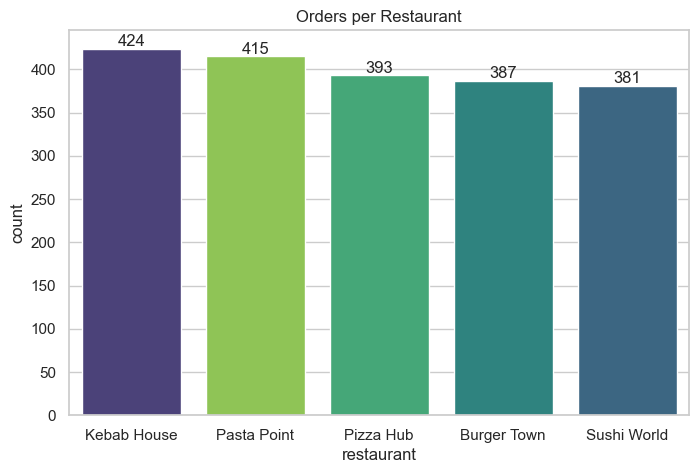

In [4]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="restaurant", order=order, palette="viridis", hue="restaurant", legend=False)
for c in ax.containers: ax.bar_label(c)
plt.title("Orders per Restaurant"); plt.show()

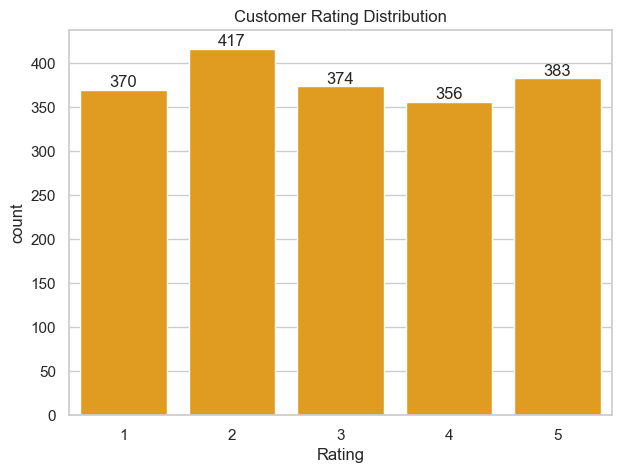

In [5]:
rated = df.dropna(subset=["rating"])
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=rated.rating.astype(int), color="orange")
for c in ax.containers: ax.bar_label(c)
plt.title("Customer Rating Distribution"); plt.xlabel("Rating"); plt.show()

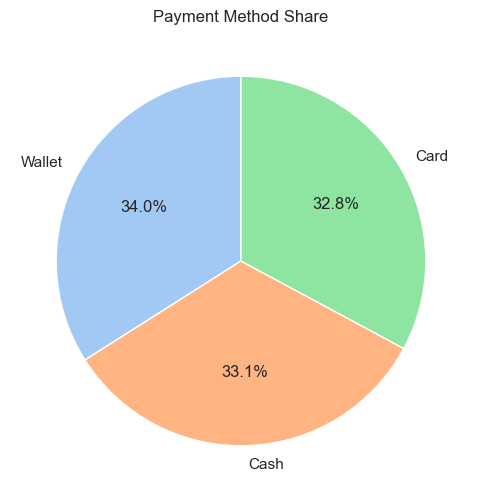

In [6]:
pay = df.payment_method.value_counts()
plt.figure(figsize=(6, 6))
plt.pie(pay, labels=pay.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
plt.title("Payment Method Share"); plt.show()

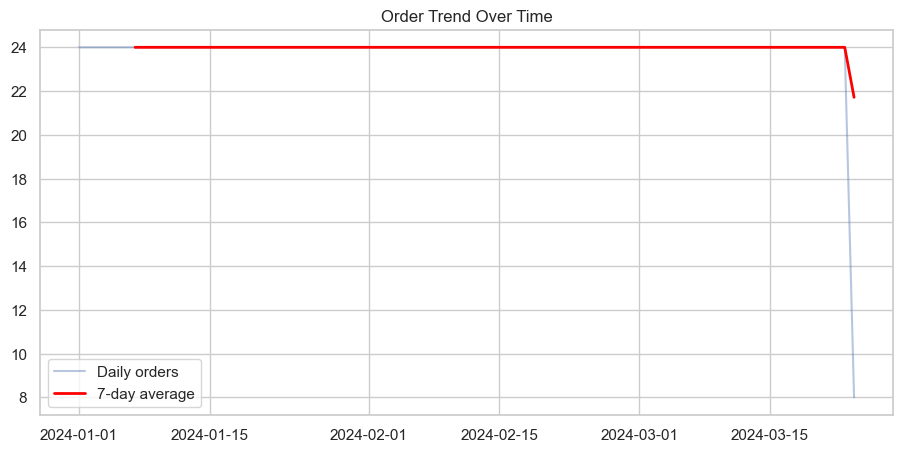

In [7]:
daily = df.set_index("order_date").resample("D").size()
plt.figure(figsize=(11, 5))
plt.plot(daily.index, daily.values, alpha=0.4, label="Daily orders")
plt.plot(daily.index, daily.rolling(7).mean(), color="red", linewidth=2, label="7-day average")
plt.title("Order Trend Over Time"); plt.legend(); plt.show()

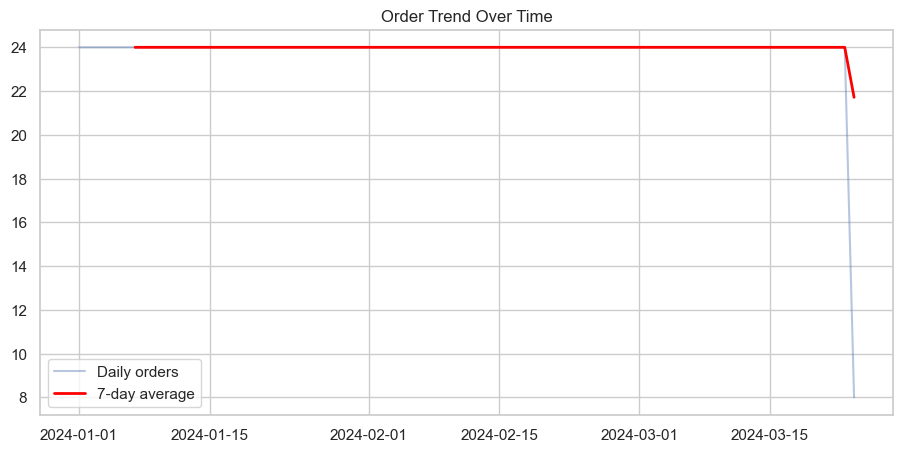

In [8]:
daily = df.set_index("order_date").resample("D").size()
plt.figure(figsize=(11, 5))
plt.plot(daily.index, daily.values, alpha=0.4, label="Daily orders")
plt.plot(daily.index, daily.rolling(7).mean(), color="red", linewidth=2, label="7-day average")
plt.title("Order Trend Over Time"); plt.legend(); plt.show()

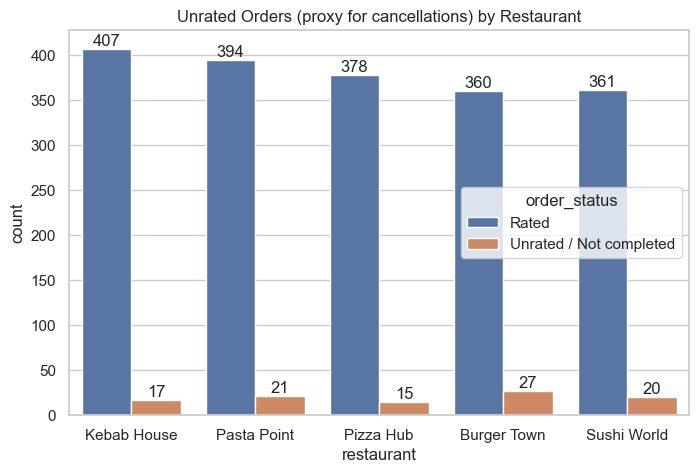

In [9]:
df["order_status"] = np.where(df.rating.isna(), "Unrated / Not completed", "Rated")
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="restaurant", hue="order_status", order=order)
for c in ax.containers: ax.bar_label(c)
plt.title("Unrated Orders (proxy for cancellations) by Restaurant"); plt.show()

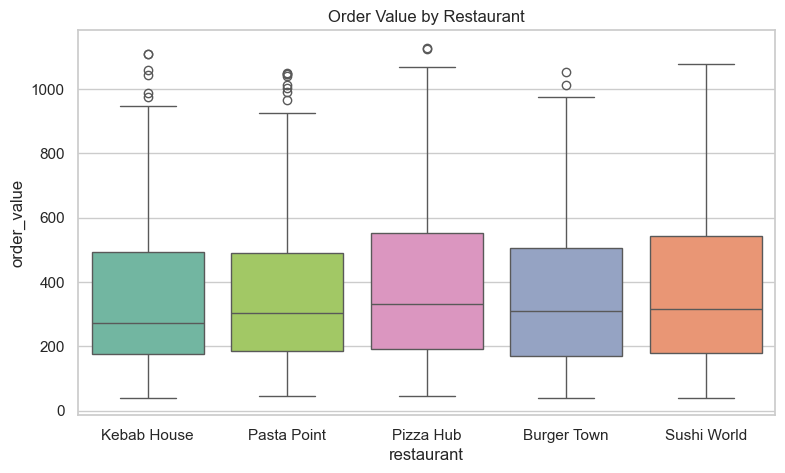

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="restaurant", y="order_value", order=order, palette="Set2", hue="restaurant", legend=False)
plt.title("Order Value by Restaurant"); plt.show()

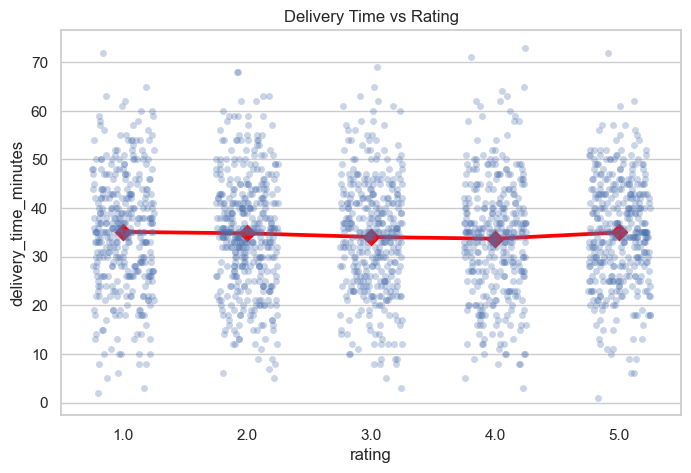

In [11]:
plt.figure(figsize=(8, 5))
sns.stripplot(data=rated, x="rating", y="delivery_time_minutes", alpha=0.3, jitter=0.25)
sns.pointplot(data=rated, x="rating", y="delivery_time_minutes", color="red", errorbar=None, markers="D")
plt.title("Delivery Time vs Rating"); plt.show()

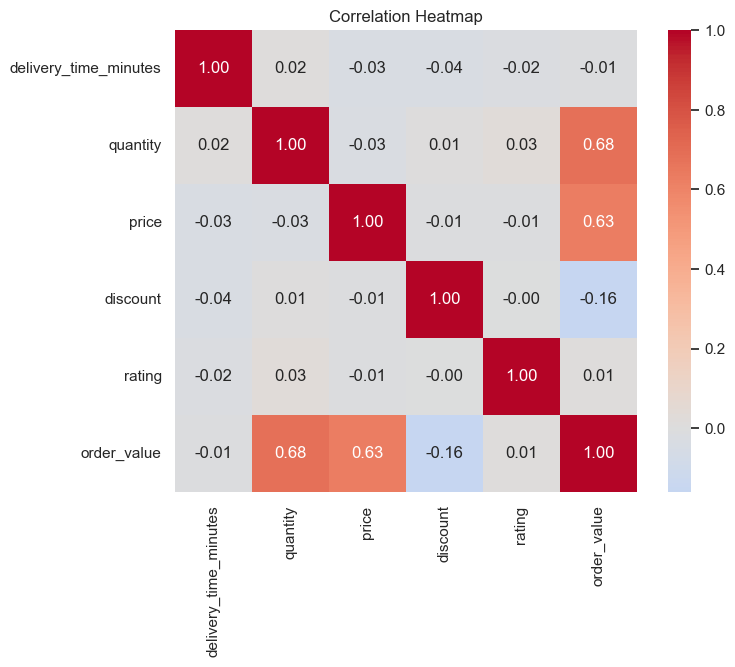

In [12]:
num_cols = ["delivery_time_minutes", "quantity", "price", "discount", "rating", "order_value"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap"); plt.show()

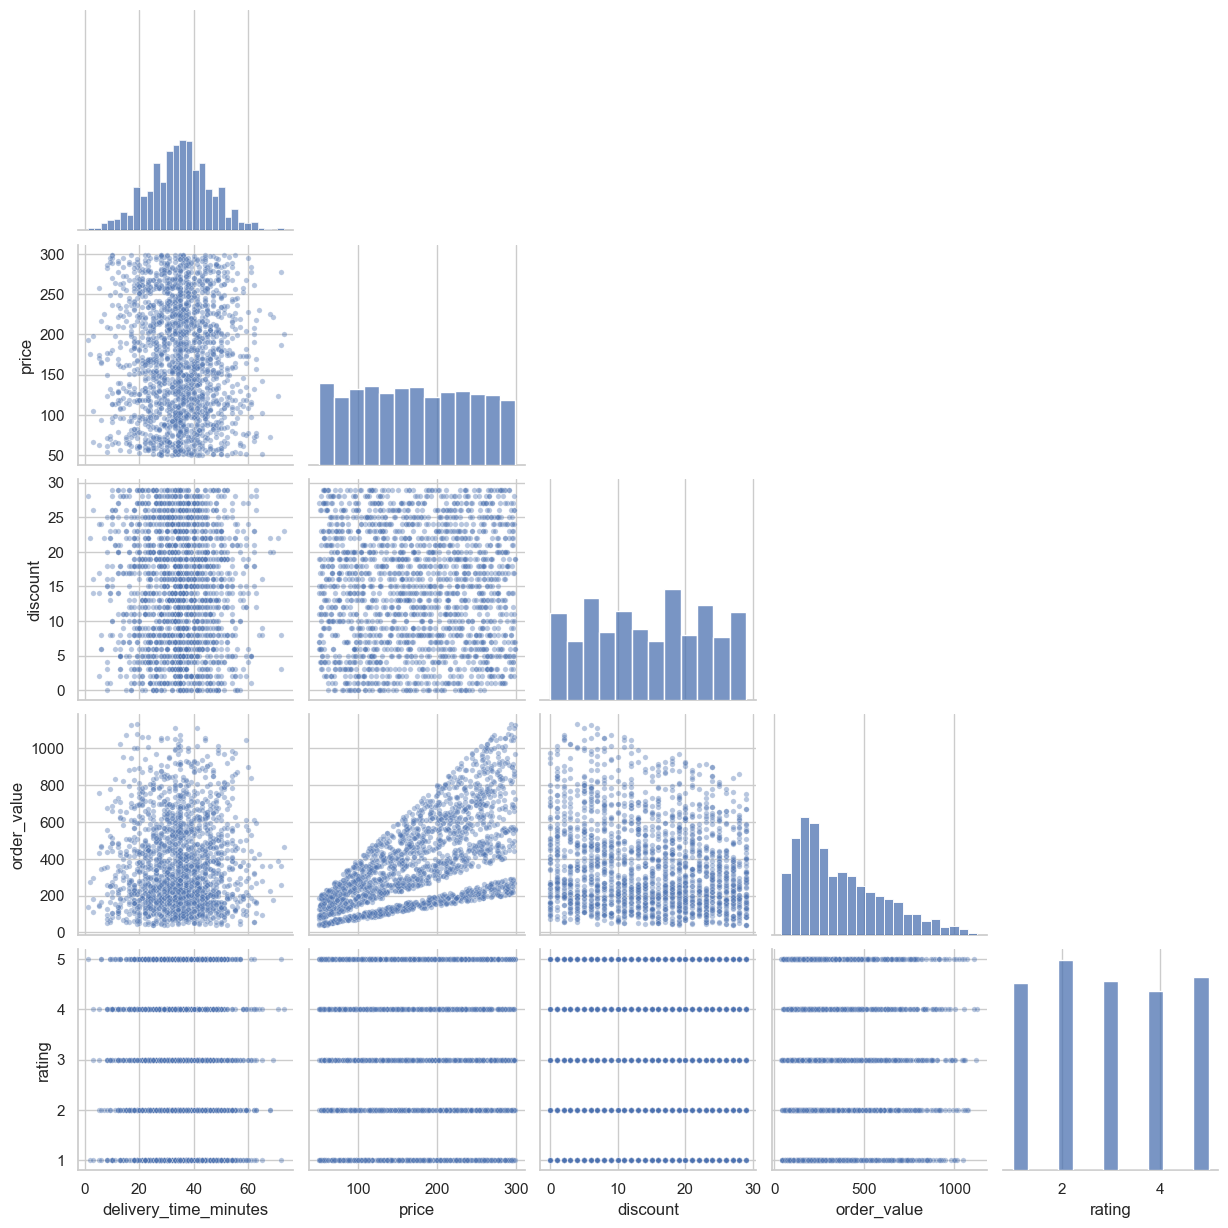

In [13]:
sns.pairplot(df[["delivery_time_minutes", "price", "discount", "order_value", "rating"]].dropna(),
             corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.show()